## Wczytanie obrazów i zamiana na macierze

W pierwszym etapie projektu wykorzystano:
- 10 zdjęć rzeczywistych,
- 10 obrazów wygenerowanych przez sztuczną inteligencję.

Wszystkie obrazy zostały przekształcone do skali szarości, dzięki czemu każdy obraz jest reprezentowany przez jedną macierz intensywności pikseli. Następnie otrzymane macierze zostaną wykorzystane do analizy z użyciem rozkładu wartości osobliwych (SVD).

W celu umożliwienia porównywania obrazów wszystkie zdjęcia zostały przeskalowane do jednakowego rozmiaru \(1024 x 1024\) pikseli. Operacja ta nie powoduje przycięcia obrazu — cały obraz zostaje zachowany, jednak jego proporcje mogą zostać nieznacznie zmienione poprzez rozciągnięcie lub ściśnięcie do formatu kwadratowego.

Dzięki temu każdy obraz jest reprezentowany przez macierz o tych samych wymiarach, co pozwala na przeprowadzenie spójnej analizy matematycznej.

Po zamianie obrazu do skali szarości każdy piksel jest reprezentowany przez jedną liczbę z przedziału od \(0\) do \(255\):
- \(0\) oznacza kolor czarny,
- \(255\) oznacza kolor biały,
- wartości pośrednie odpowiadają różnym odcieniom szarości.

W rezultacie każdy obraz można interpretować jako macierz liczb opisujących jasność poszczególnych pikseli.

In [9]:
from PIL import Image
import numpy as np
import os

real_matrices = []
ai_matrices = []

# obrazy rzeczywiste
for filename in os.listdir("real"):
    path = os.path.join("real", filename)

    img = Image.open(path).convert("L")
    img = img.resize((1024, 1024))

    A = np.array(img)

    real_matrices.append(A)

# obrazy AI
for filename in os.listdir("ai"):
    path = os.path.join("ai", filename)

    img = Image.open(path).convert("L")
    img = img.resize((1024, 1024))

    A = np.array(img)

    ai_matrices.append(A)

print("Liczba obrazów rzeczywistych:", len(real_matrices))
print("Liczba obrazów AI:", len(ai_matrices))

print("Rozmiar pojedynczej macierzy:", real_matrices[0].shape)

Liczba obrazów rzeczywistych: 10
Liczba obrazów AI: 10
Rozmiar pojedynczej macierzy: (1024, 1024)


W analizie wykorzystano obrazy o rozdzielczości \(1024 x 1024\) pikseli. Taki rozmiar pozwala zachować dużą ilość szczegółów obrazu, dzięki czemu różnice pomiędzy obrazami rzeczywistymi a wygenerowanymi przez sztuczną inteligencję są nadal widoczne gołym okiem.

Jednocześnie wszystkie obrazy posiadają identyczne wymiary, co umożliwia ich bezpośrednie porównywanie oraz przeprowadzenie spójnej analizy matematycznej z użyciem rozkładu wartości osobliwych (SVD).

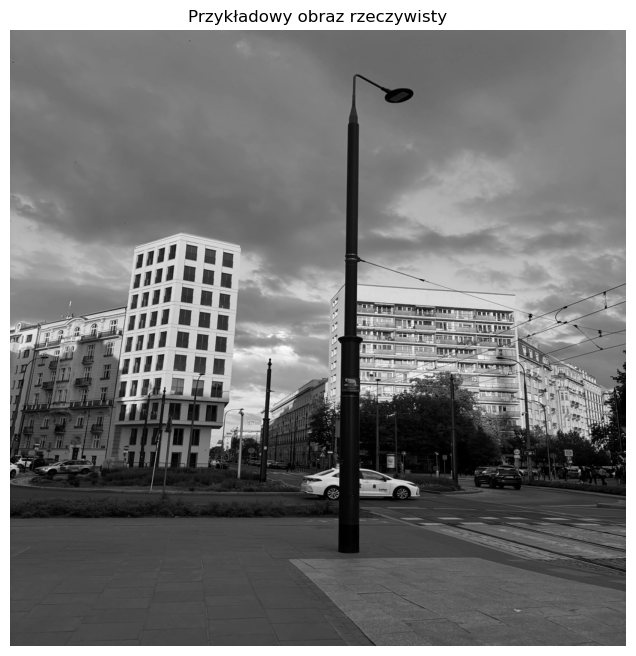

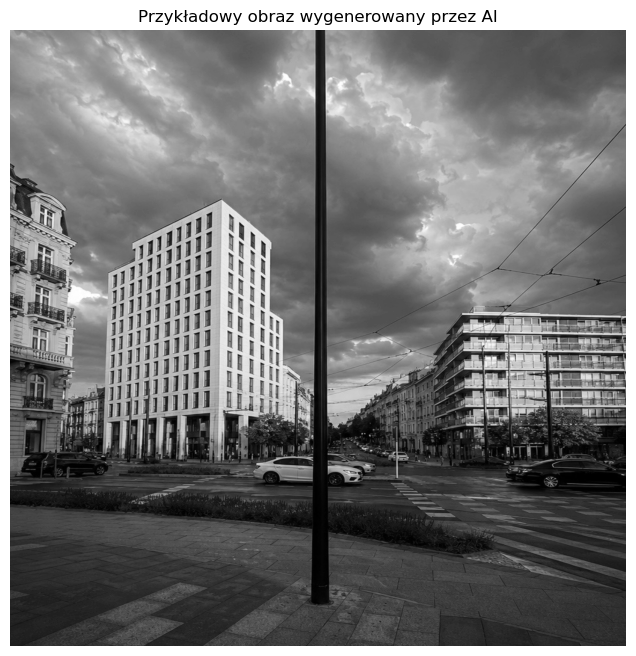

In [13]:
import matplotlib.pyplot as plt

# przykładowy obraz rzeczywisty
plt.figure(figsize=(8,8))
plt.imshow(real_matrices[0], cmap="gray")
plt.title("Przykładowy obraz rzeczywisty")
plt.axis("off")
plt.show()

# przykładowy obraz AI
plt.figure(figsize=(8,8))
plt.imshow(ai_matrices[0], cmap="gray")
plt.title("Przykładowy obraz wygenerowany przez AI")
plt.axis("off")
plt.show()

## Rozkład SVD macierzy obrazów

Po przekształceniu obrazów do postaci macierzy intensywności pikseli wykonano dla każdej macierzy rozkład SVD (Singular Value Decomposition).

Dla dowolnej macierzy $A$ rozkład SVD ma postać:

$$
A = U \Sigma Q^T
$$

gdzie:
- $U$ oraz $Q$ są macierzami ortogonalnymi,
- $\Sigma$ jest macierzą diagonalną zawierającą wartości osobliwe macierzy $A$.

Wartości osobliwe opisują siłę rozciągania macierzy w odpowiednich kierunkach i stanowią najważniejszy element analizy obrazów metodą SVD.

Dla każdego obrazu zapisano:
- macierz $U$,
- wektor wartości osobliwych $S$,
- macierz $Q^T$.

Rozkład został wykonany osobno dla obrazów rzeczywistych oraz obrazów wygenerowanych przez sztuczną inteligencję.

# Konstrukcja rozkładu SVD (skąd to się bierze)

## 1. Własności macierzy $A^TA$

Niech:

$$
A \in \mathbb{R}^{n \times n}
$$

Rozważamy macierz:

$$
A^TA
$$

Jest ona symetryczna, ponieważ:

$$
(A^TA)^T = A^TA
$$

Z twierdzenia spektralnego każda rzeczywista macierz symetryczna jest diagonalizowalna ortogonalnie. Istnieje więc macierz ortogonalna $Q$ taka, że:

$$
A^TA = QDQ^T
$$

gdzie:
- $Q$ jest macierzą ortogonalną,
- $D$ jest macierzą diagonalną.

---

## 2. Wartości osobliwe

Ponadto dla dowolnego $x \in \mathbb{R}^n$:

$$
x^TA^TAx = (Ax)^T(Ax) = \|Ax\|^2 \geq 0
$$

Zatem wszystkie wartości własne macierzy $A^TA$ są nieujemne.

Możemy więc zapisać:

$$
D = \Sigma^2
$$

czyli:

$$
A^TA = Q\Sigma^2Q^T
$$

Macierz:

$$
\Sigma = \operatorname{diag}(\sigma_1, \dots, \sigma_n)
$$

zawiera wartości osobliwe macierzy $A$, gdzie:

$$
\sigma_i = \sqrt{\lambda_i}
$$

---

## 3. Wektory własne

Niech $q_i$ oznacza $i$-tą kolumnę macierzy $Q$. Wtedy:

$$
A^TAq_i = \sigma_i^2q_i
$$

Rozważmy normę wektora $Aq_i$:

$$
\|Aq_i\|^2
=
(Aq_i)^T(Aq_i)
=
q_i^TA^TAq_i
=
\sigma_i^2
$$

czyli:

$$
\|Aq_i\| = \sigma_i
$$

---

## 4. Konstrukcja macierzy $U$

Definiujemy:

$$
u_i = \frac{Aq_i}{\sigma_i}
$$

Wówczas:

$$
Aq_i = \sigma_i u_i
$$

Budujemy macierz:

$$
U =
\begin{bmatrix}
u_1 & \cdots & u_n
\end{bmatrix}
$$

---

## 5. Otrzymanie rozkładu SVD

Ponieważ macierz $Q$ ma kolumny $q_i$, otrzymujemy:

$$
AQ =
\begin{bmatrix}
Aq_1 & \cdots & Aq_n
\end{bmatrix}
$$

Korzystając z zależności:

$$
Aq_i = \sigma_i u_i
$$

dostajemy:

$$
AQ =
\begin{bmatrix}
\sigma_1u_1 & \cdots & \sigma_nu_n
\end{bmatrix}
=
U\Sigma
$$

czyli:

$$
AQ = U\Sigma
$$

Ponieważ $Q$ jest macierzą ortogonalną:

$$
Q^{-1} = Q^T
$$

możemy pomnożyć obustronnie przez $Q^T$:

$$
A = U\Sigma Q^T
$$

co kończy konstrukcję rozkładu SVD.

# Interpretacja geometryczna

Rozkład SVD można interpretować jako:

1. obrót przestrzeni,
2. skalowanie osi,
3. kolejny obrót.

Macierz `A` przekształca przestrzeń poprzez:

x → Vᵀ → Σ → U

czyli:
- najpierw obrót,
- potem skalowanie,
- na końcu kolejny obrót.

---

# Macierz Vᵀ

Macierz `Vᵀ`:

- wybiera najważniejsze kierunki w danych wejściowych,
- odpowiada za obrót przestrzeni wejściowej,
- zawiera prawe wektory osobliwe.

Kolumny macierzy `V` tworzą ortonormalną bazę kierunków danych.

W analizie obrazów często odpowiadają za poziome struktury i wzorce.

---

# Macierz Σ

Macierz `Σ` zawiera wartości osobliwe:

σ₁ ≥ σ₂ ≥ ... ≥ σₙ ≥ 0

Wartości osobliwe określają:

- ilość energii/informacji w danym kierunku,
- znaczenie poszczególnych komponentów.

Duże wartości osobliwe:
- odpowiadają dominującym strukturom danych.

Małe wartości osobliwe:
- opisują drobne detale lub szum.

---

# Macierz U

Macierz `U`:

- opisuje przestrzeń wyjściową,
- wykonuje końcowy obrót danych,
- zawiera lewe wektory osobliwe.

Kolumny `U` definiują główne kierunki danych po transformacji.

W obrazach często odpowiadają pionowym strukturom.

---

# Interpretacja wartości osobliwych

Wartości osobliwe opisują rozkład energii danych.

Jeżeli wartości osobliwe:

- spadają szybko,
  - dane są bardziej regularne,
  - większość informacji znajduje się w kilku komponentach.

- spadają wolniej,
  - dane mają bardziej złożoną strukturę,
  - energia jest rozłożona pomiędzy większą liczbą komponentów.

---

# Analiza wykresu spadku wartości osobliwych

Na wykresie:

- oś X oznacza numer wartości osobliwej,
- oś Y oznacza wartość osobliwą.

Logarytmiczna skala osi Y pozwala lepiej obserwować tempo spadku wartości osobliwych.



In [12]:
import numpy as np

real_svd = []
ai_svd = []

# SVD dla obrazów rzeczywistych
for A in real_matrices:
    U, S, QT = np.linalg.svd(A, full_matrices=False)
    real_svd.append((U, S, QT))

# SVD dla obrazów AI
for A in ai_matrices:
    U, S, QT = np.linalg.svd(A, full_matrices=False)
    ai_svd.append((U, S, QT))

print("Liczba rozkładów SVD dla obrazów rzeczywistych:", len(real_svd))
print("Liczba rozkładów SVD dla obrazów AI:", len(ai_svd))

print("Rozmiary przykładowego rozkładu SVD:")
print("U:", real_svd[0][0].shape)
print("S:", real_svd[0][1].shape)
print("QT:", real_svd[0][2].shape)

Liczba rozkładów SVD dla obrazów rzeczywistych: 10
Liczba rozkładów SVD dla obrazów AI: 10
Rozmiary przykładowego rozkładu SVD:
U: (1024, 1024)
S: (1024,)
QT: (1024, 1024)


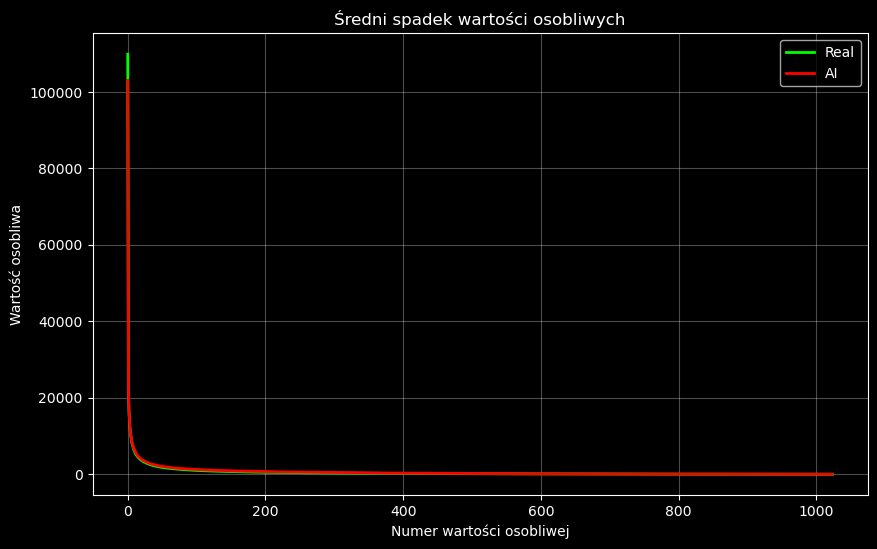

In [36]:
import numpy as np
import matplotlib.pyplot as plt

# ciemne tło
plt.style.use('dark_background')

# 1. Pobranie wartości osobliwych
real_singular_values = [svd[1] for svd in real_svd]
ai_singular_values = [svd[1] for svd in ai_svd]

# 2. Średnie wartości osobliwe
mean_real_s = np.mean(real_singular_values, axis=0)
mean_ai_s = np.mean(ai_singular_values, axis=0)

# 3. Wykres średniego spadku wartości osobliwych
plt.figure(figsize=(10, 6))

# Real = zielony
plt.plot(
    mean_real_s,
    color='lime',
    linewidth=2,
    label="Real"
)

# AI = czerwony
plt.plot(
    mean_ai_s,
    color='red',
    linewidth=2,
    label="AI"
)

plt.title("Średni spadek wartości osobliwych")
plt.xlabel("Numer wartości osobliwej")
plt.ylabel("Wartość osobliwa")

plt.grid(True, alpha=0.3)
plt.legend()

plt.show()

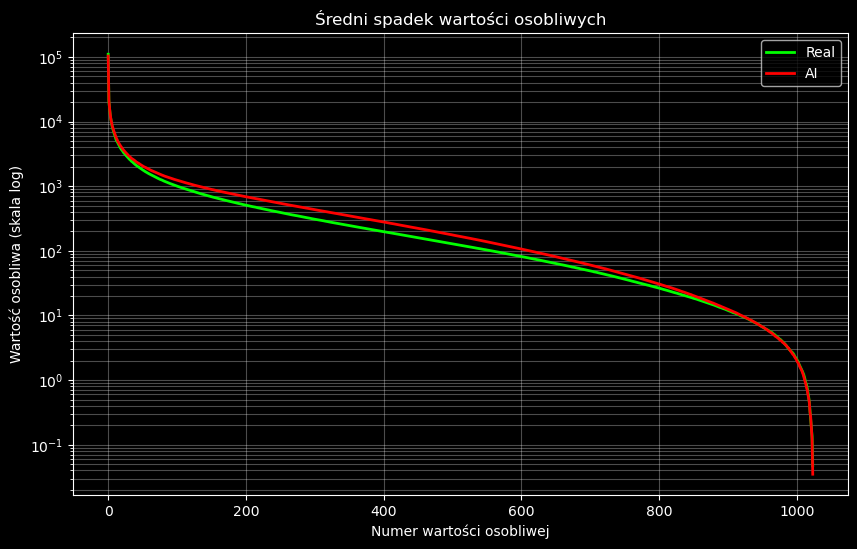

In [35]:
import numpy as np
import matplotlib.pyplot as plt

# ciemne tło
plt.style.use('dark_background')

# 1. Pobranie wartości osobliwych
real_singular_values = [svd[1] for svd in real_svd]
ai_singular_values = [svd[1] for svd in ai_svd]

# 2. Średnie wartości osobliwe
mean_real_s = np.mean(real_singular_values, axis=0)
mean_ai_s = np.mean(ai_singular_values, axis=0)

# 3. Wykres średniego spadku wartości osobliwych
plt.figure(figsize=(10, 6))

# Real = zielony
plt.plot(
    mean_real_s,
    color='lime',
    linewidth=2,
    label="Real"
)

# AI = czerwony
plt.plot(
    mean_ai_s,
    color='red',
    linewidth=2,
    label="AI"
)

# logarytmiczna oś Y
plt.yscale('log')

plt.title("Średni spadek wartości osobliwych")
plt.xlabel("Numer wartości osobliwej")
plt.ylabel("Wartość osobliwa (skala log)")

plt.grid(True, which="both", alpha=0.3)
plt.legend()

plt.show()

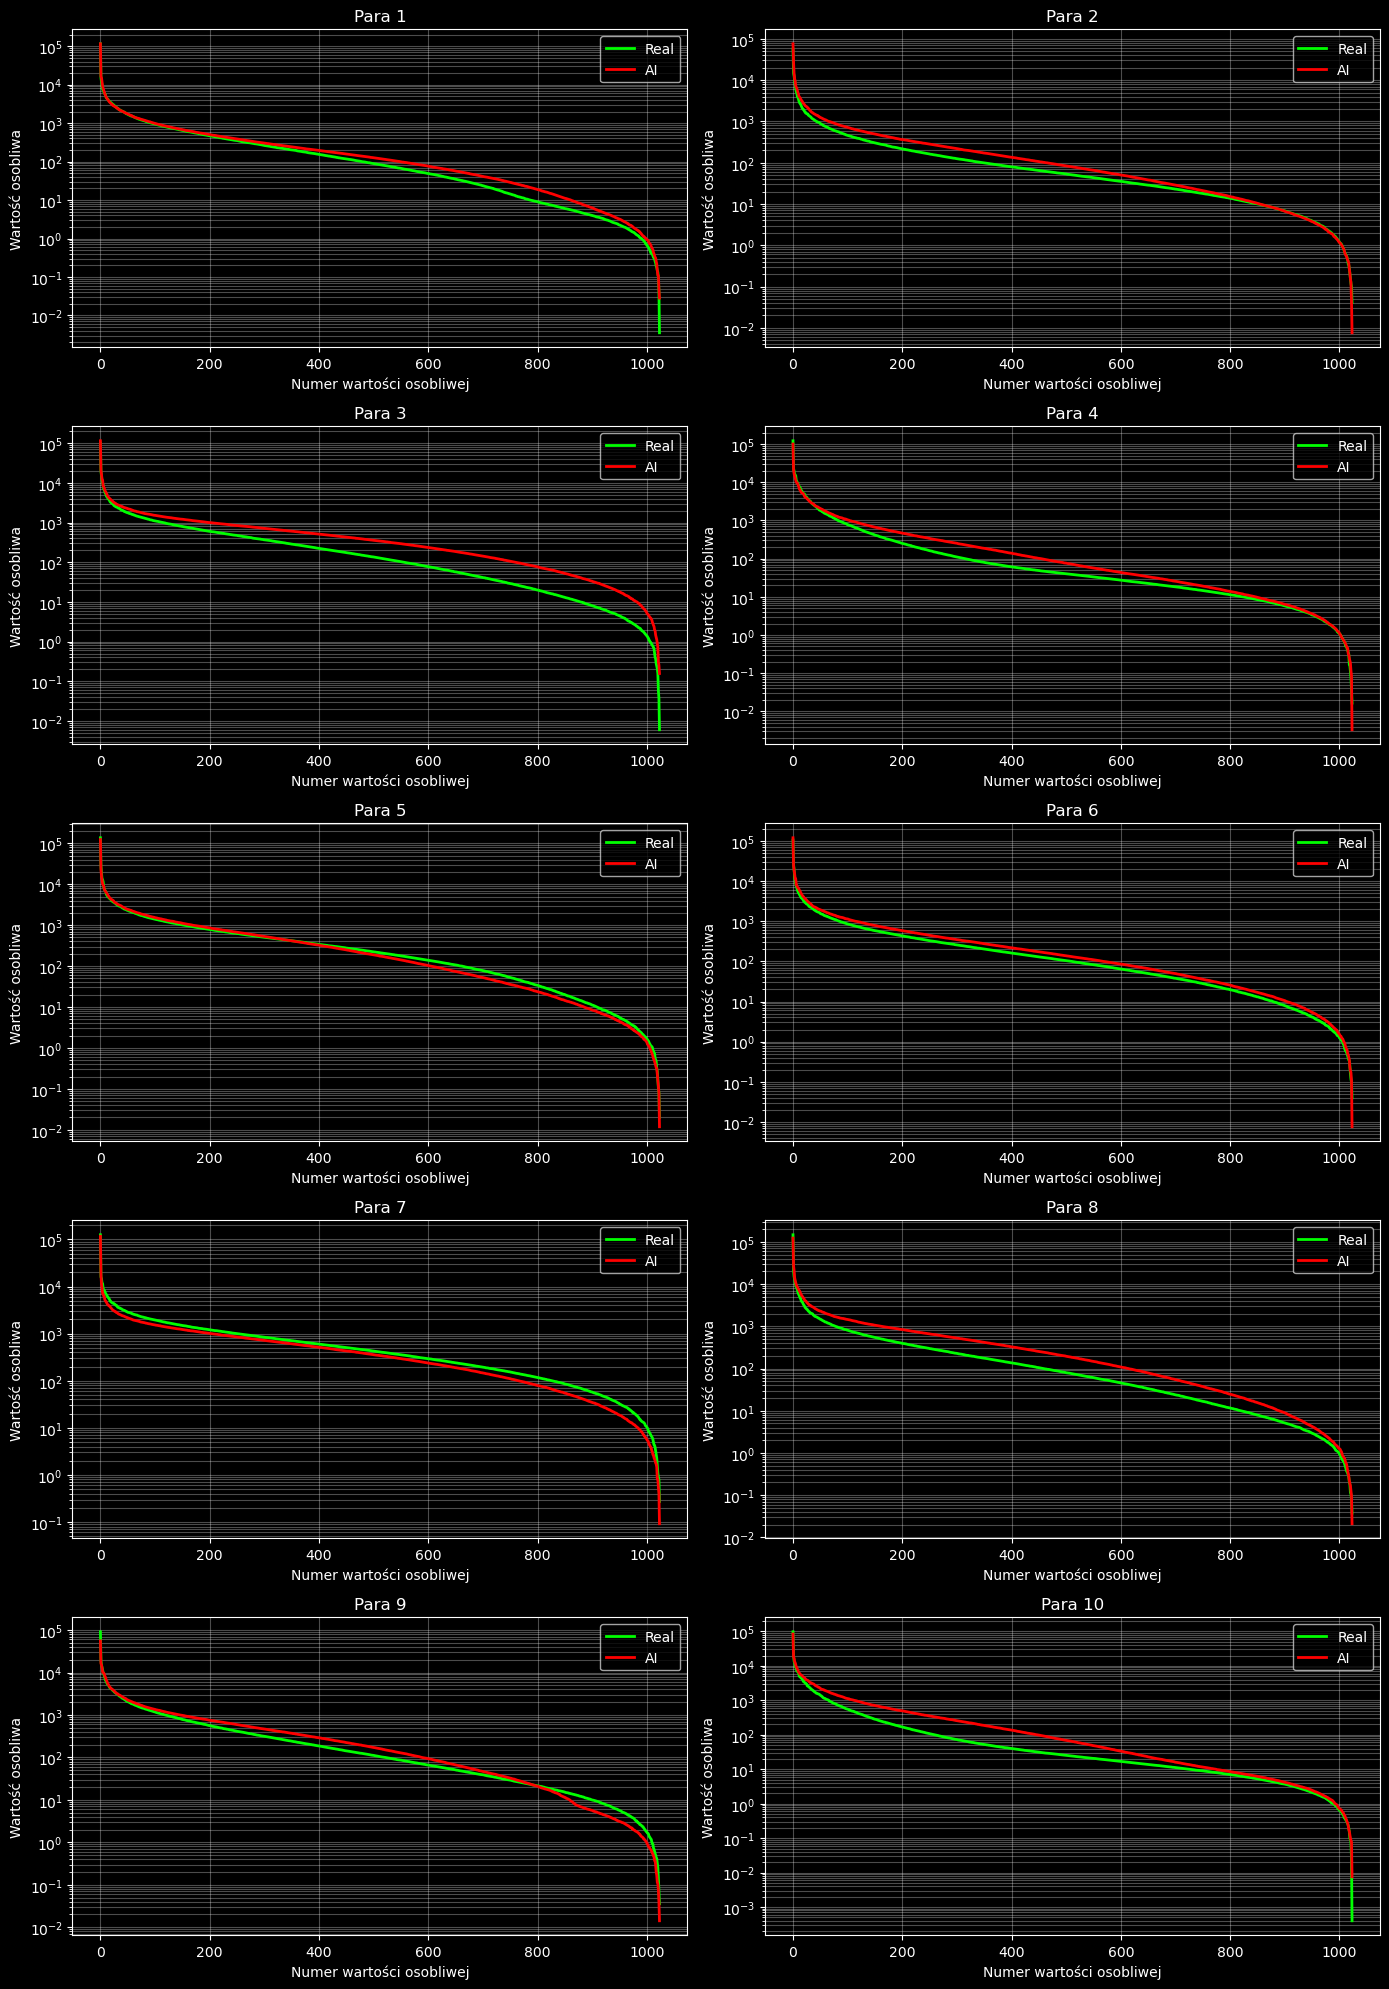

In [34]:
import numpy as np
import matplotlib.pyplot as plt

# ciemne tło
plt.style.use('dark_background')

# Plansza 5x2 = 10 wykresów
fig, axes = plt.subplots(5, 2, figsize=(14, 20))

axes = axes.flatten()

for i in range(10):

    # wartości osobliwe dla i-tej pary
    real_s = real_svd[i][1]
    ai_s = ai_svd[i][1]

    ax = axes[i]

    # Real = zielony
    ax.plot(
        real_s,
        color='lime',
        linewidth=2,
        label="Real"
    )

    # AI = czerwony
    ax.plot(
        ai_s,
        color='red',
        linewidth=2,
        label="AI"
    )

    # logarytmiczna oś Y
    ax.set_yscale('log')

    ax.set_title(f"Para {i+1}")
    ax.set_xlabel("Numer wartości osobliwej")
    ax.set_ylabel("Wartość osobliwa")

    ax.grid(True, which="both", alpha=0.3)
    ax.legend()

# poprawa układu
plt.tight_layout()

plt.show()

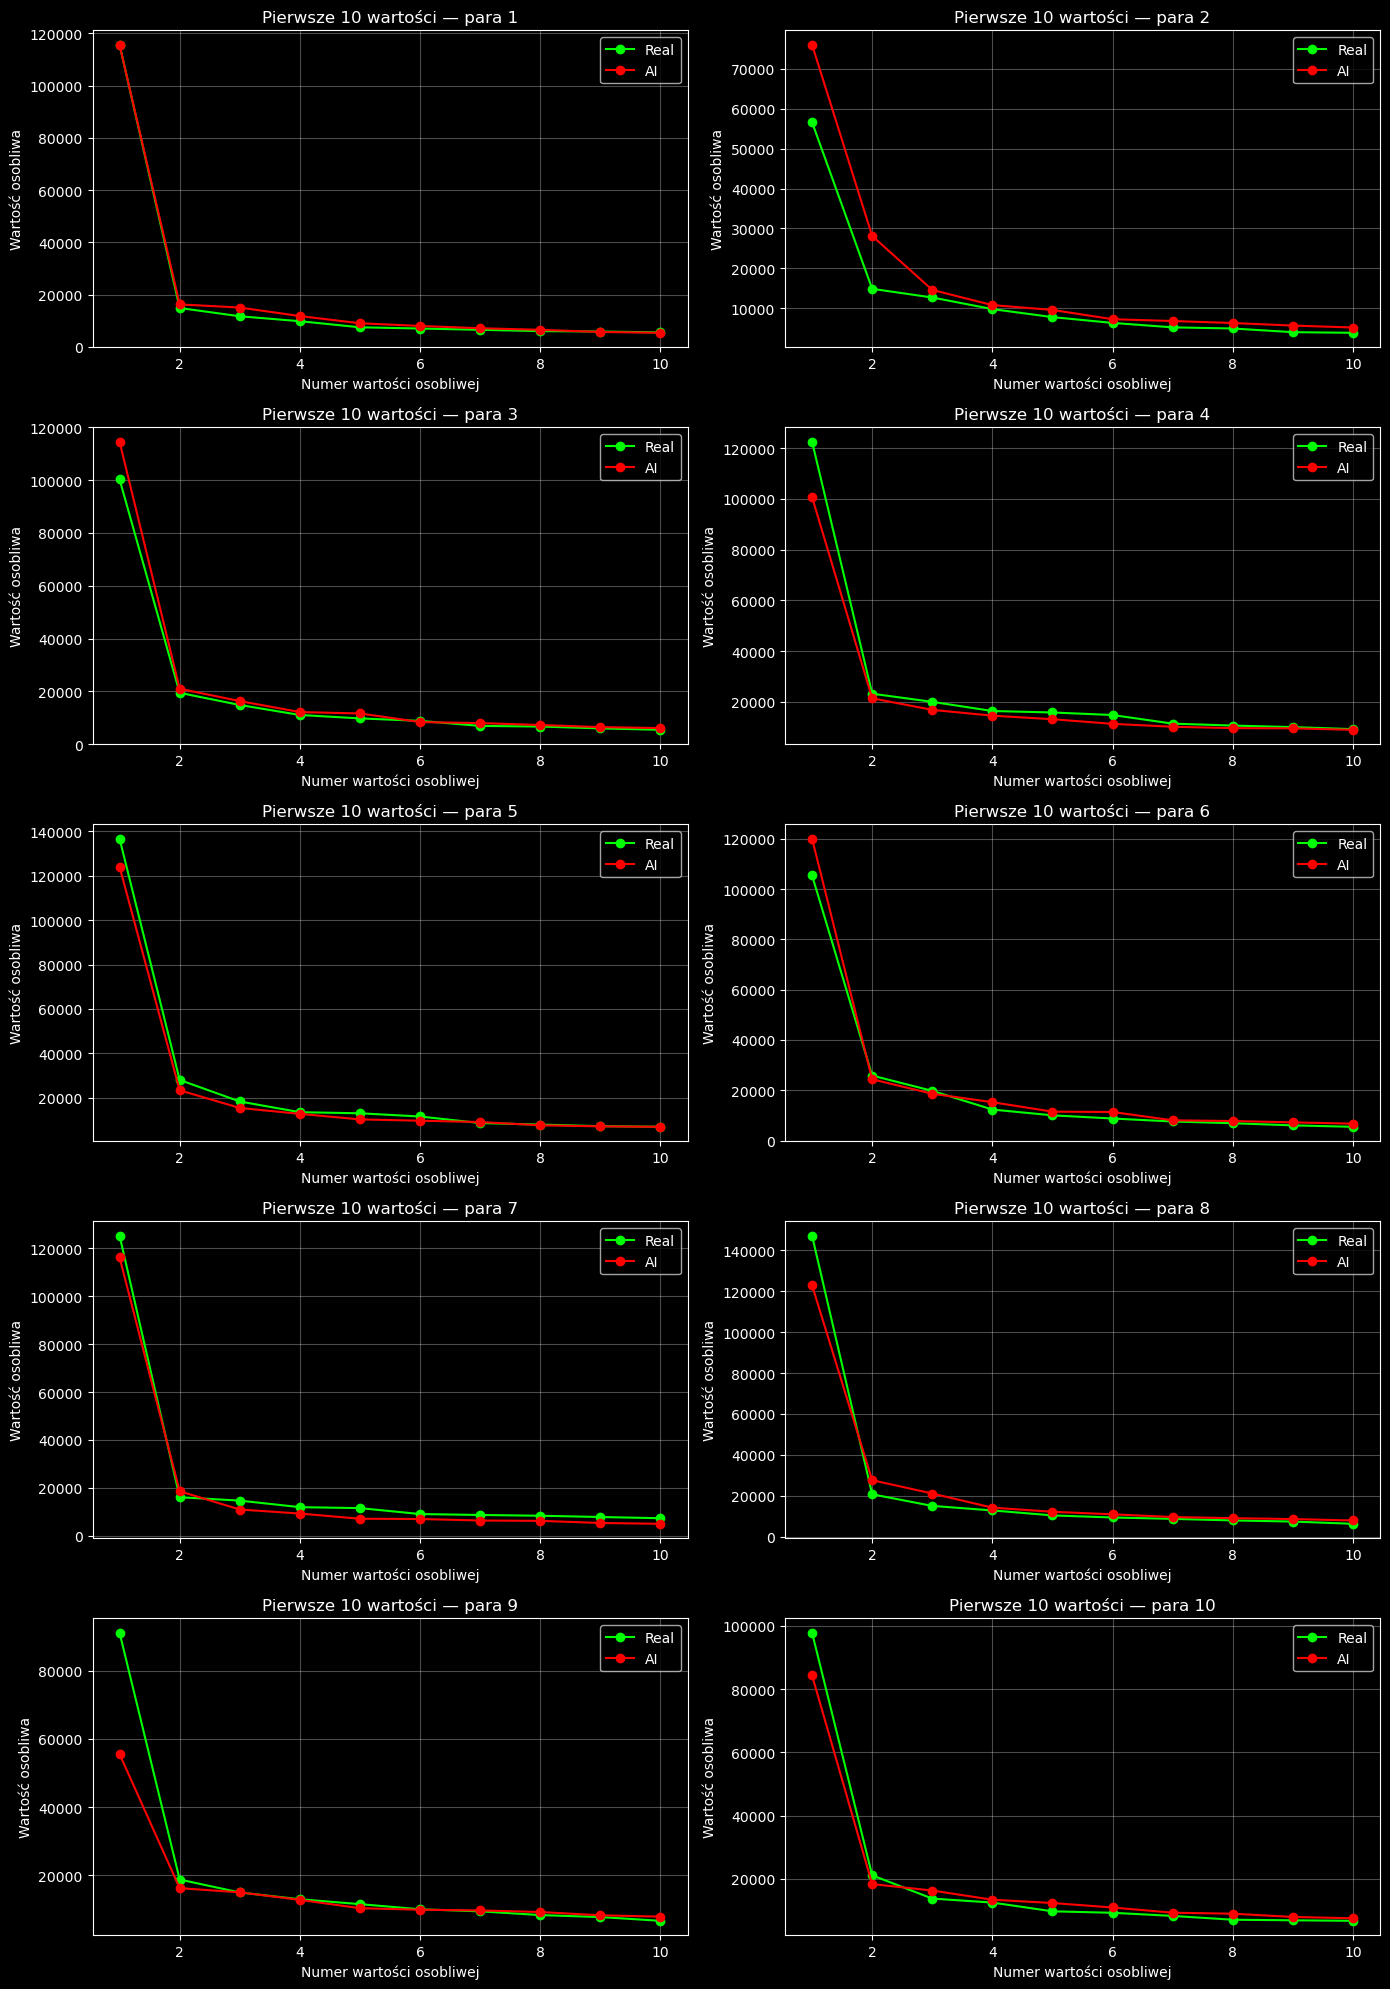

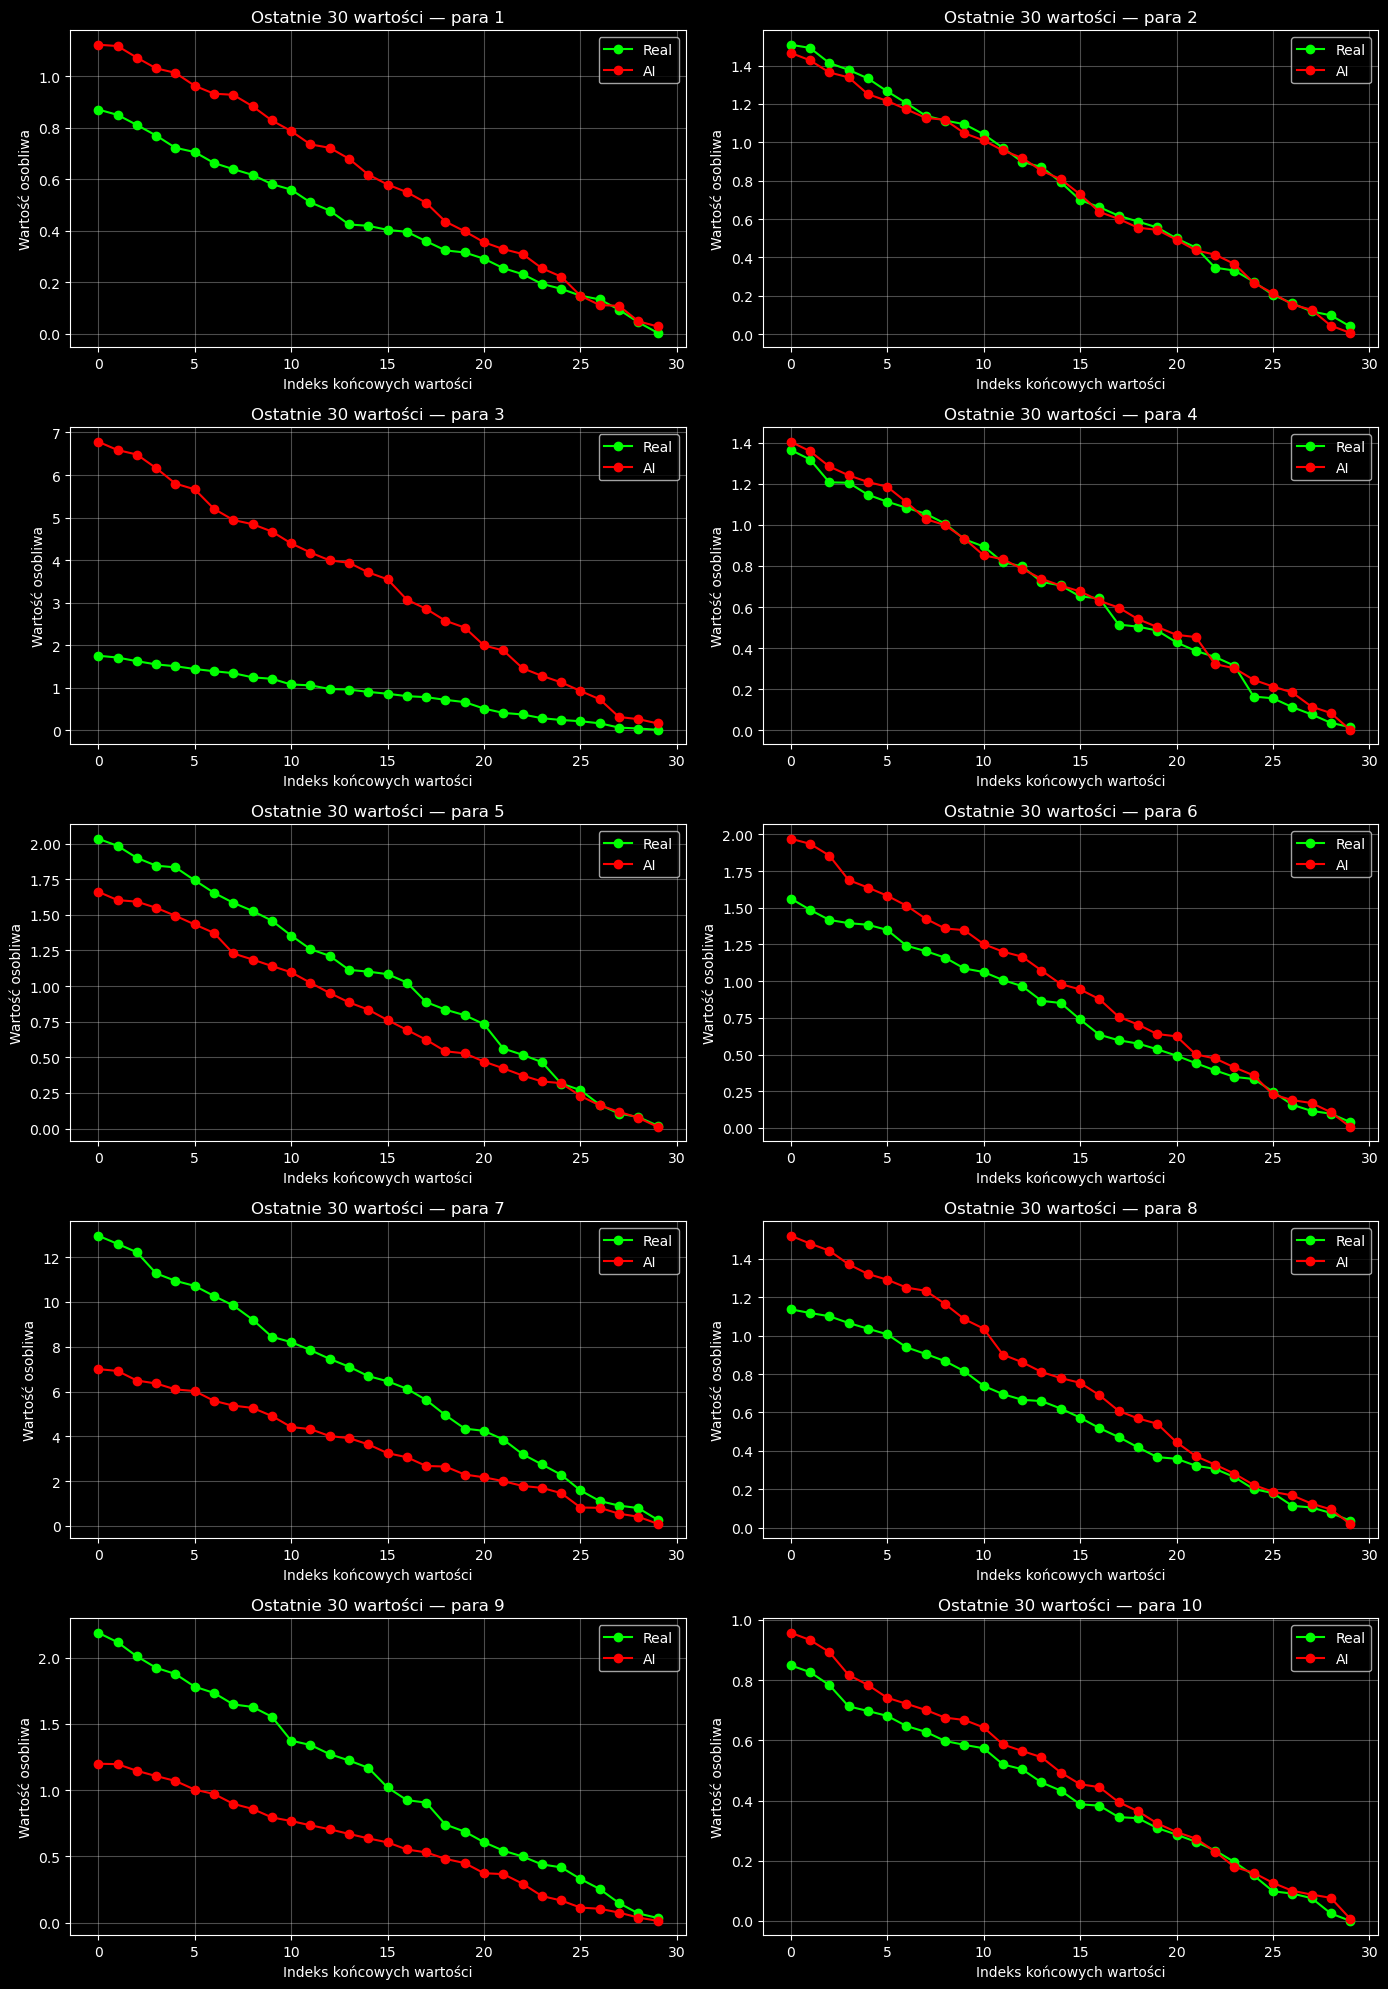

In [33]:
import numpy as np
import matplotlib.pyplot as plt

# ciemny styl matplotlib
plt.style.use('dark_background')

# liczba pierwszych i ostatnich wartości osobliwych
k_first = 10
k_last = 30

# =========================
# PIERWSZE 10 WARTOŚCI
# =========================

fig, axes = plt.subplots(5, 2, figsize=(14, 20))
axes = axes.flatten()

for i in range(10):

    real_s = real_svd[i][1][:k_first]
    ai_s = ai_svd[i][1][:k_first]

    ax = axes[i]

    # Real = zielony
    ax.plot(
        range(1, k_first + 1),
        real_s,
        marker='o',
        color='lime',
        label='Real'
    )

    # AI = czerwony
    ax.plot(
        range(1, k_first + 1),
        ai_s,
        marker='o',
        color='red',
        label='AI'
    )

    ax.set_title(f"Pierwsze {k_first} wartości — para {i+1}")
    ax.set_xlabel("Numer wartości osobliwej")
    ax.set_ylabel("Wartość osobliwa")

    ax.grid(True, alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

# =========================
# OSTATNIE WARTOŚCI
# =========================

fig, axes = plt.subplots(5, 2, figsize=(14, 20))
axes = axes.flatten()

for i in range(10):

    real_s = real_svd[i][1][-k_last:]
    ai_s = ai_svd[i][1][-k_last:]

    ax = axes[i]

    # Real = zielony
    ax.plot(
        range(len(real_s)),
        real_s,
        marker='o',
        color='lime',
        label='Real'
    )

    # AI = czerwony
    ax.plot(
        range(len(ai_s)),
        ai_s,
        marker='o',
        color='red',
        label='AI'
    )

    ax.set_title(f"Ostatnie {k_last} wartości — para {i+1}")
    ax.set_xlabel("Indeks końcowych wartości")
    ax.set_ylabel("Wartość osobliwa")

    ax.grid(True, alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()


# Interpretacja dla danych Real i AI: spadek wartości osobliwych

# Interpretacja wartości osobliwych

Wartości osobliwe opisują:

- ilość informacji i energii w danych,
- złożoność struktury obrazu,
- znaczenie poszczególnych komponentów.

Duże wartości osobliwe:
- odpowiadają dominującym globalnym strukturom obrazu.

Małe wartości osobliwe:
- odpowiadają detalom,
- teksturom,
- drobnym nieregularnościom,
- szumowi.

---

# Średni spadek wartości osobliwych

## Wykres liniowy

Na wykresie liniowym widoczny jest bardzo gwałtowny spadek pierwszych wartości osobliwych.

Oznacza to, że:

- większość energii obrazu znajduje się w kilku pierwszych komponentach,
- obrazy mają silną strukturę globalną,
- dane nie są losowym szumem.

Pierwsza wartość osobliwa jest wielokrotnie większa od kolejnych, co wskazuje na dominację głównych struktur obrazu.

---

## Wykres logarytmiczny

Po zastosowaniu skali logarytmicznej możliwe było dokładniejsze przeanalizowanie całego widma wartości osobliwych.

Zaobserwowano:

- niemal liniowy przebieg środkowej części widma,
- bardzo podobny kształt krzywych dla `Real` i `AI`,
- systematyczne przesunięcie krzywej `AI` powyżej `Real`.

Oznacza to, że:

- obrazy AI mają bardziej rozproszoną energię,
- większa liczba komponentów zawiera istotną informację,
- struktura AI jest bardziej regularna i mniej skoncentrowana.

---

# Analiza poszczególnych par obrazów

Analiza wszystkich 10 par wykazała dużą spójność wyników.

W większości przypadków:

- krzywa `AI` znajduje się powyżej `Real`,
- spadek dla `AI` jest wolniejszy,
- obrazy AI utrzymują większe wartości osobliwe w środkowej części widma.

Największe różnice widoczne są w zakresie:

- około 100–800 wartości osobliwych.

To sugeruje, że:

- obrazy AI różnią się głównie w średnioskalowych strukturach i teksturach,
- modele generatywne zachowują więcej regularnych wzorców.

---

# Analiza pierwszych 10 wartości osobliwych

Pierwsze wartości osobliwe odpowiadają za globalną strukturę obrazu.

Zaobserwowano, że:

- pierwsze wartości osobliwe są bardzo podobne dla `Real` i `AI`,
- różnice pojawiają się głównie od 2–3 komponentu,
- obrazy AI często mają nieco większe wartości osobliwe.

Interpretacja:

- AI poprawnie odwzorowuje główną strukturę obrazu,
- różnice pojawiają się dopiero w bardziej szczegółowych komponentach.

W niektórych parach:

- `Real` posiada większą pierwszą wartość osobliwą,
- jednak dalsze wartości dla `AI` pozostają wyższe.

Może to oznaczać, że:

- AI rozkłada energię bardziej równomiernie,
- obrazy rzeczywiste mają bardziej skoncentrowaną strukturę.

---

# Analiza ostatnich 30 wartości osobliwych

Ostatnie wartości osobliwe odpowiadają za:

- drobne detale,
- mikrostruktury,
- szum,
- lokalne nieregularności.

W tej części widma zaobserwowano największe różnice pomiędzy `Real` i `AI`.

W wielu parach:

- `AI` utrzymuje większe końcowe wartości osobliwe,
- przebieg `AI` jest bardziej regularny,
- `Real` częściej wykazuje nieregularne lokalne zmiany.

Interpretacja:

- obrazy AI zawierają bardziej uporządkowane mikrostruktury,
- obrazy rzeczywiste mają bardziej naturalny i nieregularny szum,
- AI generuje bardziej gładkie i regularne tekstury.

Szczególnie widoczne jest to dla par:

- 1,
- 3,
- 6,
- 8,
- 10

---

# Główne różnice między Real i AI

## Obrazy rzeczywiste (`Real`)

Charakterystyka:

- szybszy spadek wartości osobliwych,
- bardziej skoncentrowana energia,
- bardziej nieregularny ogon widma,
- większa naturalność lokalnych struktur.

---

## Obrazy AI (`AI`)

Charakterystyka:

- wolniejszy spadek wartości osobliwych,
- bardziej rozłożona energia,
- bardziej regularny przebieg widma,
- większa regularność tekstur i struktur średniej skali.


In [39]:
# ODTĄD DO ZROBIENIA ZOSIA

# dalsze analizy:
#  Energia skumulowana 
#  Liczba wartości osobliwych potrzebna do zachowania 90%, 95% i 99% energii

#  pomysł: wywnioskowac z calej analizy na jakiej podstawie stwierdzac, ktore z dwóch zdjęć z pary real vs ai jest prawdziwe, stworzyc funkcje ktora bedzie przyjmowac 
# dwa zdjecia i wydawać werdykt: ktore z nich jest real ktore ai. nastepnie zrobic tak jak ja na poczatku kilka par zdjec real i ai (powiedzmy ze juz nie 10, tylko 5), 
# i niech ta funkcja powie ktore zdjecie z kazdej pary jest prawdziwe i zobaczyc ile poprawnie zgadla ("zgadła" no wiadomo policzyla). Z tego fragmentu mojej analizy, już widac
# ze wiekszosc zdjec ai gdzies po srodku czyli na ok. 512 wartosci osobliwej ma wiekszą wartosc, wiec to moze byc jeden z determinantów tej funkcji.

# inne rzeczy do zrobienia:
# kontynuacja prezentacji
# wyeksportowanie tego markdowna do pdf w raz z wynikami kodu (zwierzu chcial projekt zeby jakos jeden pdf wyslac)
# napisac jakis wstep i wnioski koncowe w tym notebooku
# niektore slajdy w prezentacji nie są zbyt estetyczne, jesli masz ochote mozesz je zmienic
# wszystko co uznasz ze by sie jeszcze przydalo zrobic